In [1]:
!pip install "numpy<2" qiskit qiskit-aer mqt.ddsim cirq qsimcirq quimb pyqrack matplotlib pandas

Starting Airtight Computational Throughput Benchmark (Non-Clifford)...

Building Non-Clifford Entanglement Circuit (Qubits: 16, Depth: 5)...

Running Qiskit Aer (Baseline)...
  -> Finished in 0.0385s
Running Google qsim (Optimized)...
  -> Finished in 0.0120s
Running MQT DDSIM...
  -> Finished in 9.2223s
Running Quimb (Tensor Network)...
  -> Finished in 4.9821s
Running PyQrack...
  -> Finished in 0.0439s


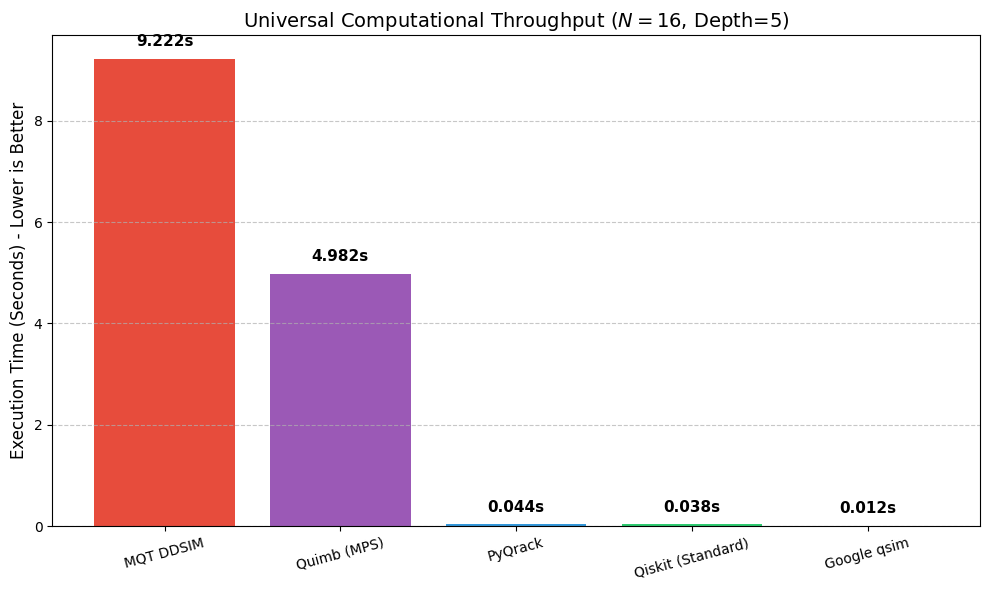


Raw Timing Data:
Emulator                  | Execution Time (Seconds)
-------------------------------------------------------
MQT DDSIM                 | 9.2223s
Quimb (MPS)               | 4.9821s
PyQrack                   | 0.0439s
Qiskit (Standard)         | 0.0385s
Google qsim               | 0.0120s


In [2]:
import time
import matplotlib.pyplot as plt
import gc

# Emulator Imports
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from mqt.ddsim import DDSIMProvider
import cirq
import qsimcirq
import quimb.tensor as qtn

print("Starting Airtight Computational Throughput Benchmark (Non-Clifford)...\n")

# Configuration for the torture test (Balanced for 16 Qubits)
N_QUBITS = 16
DEPTH = 5  
results = {}

print(f"Building Non-Clifford Entanglement Circuit (Qubits: {N_QUBITS}, Depth: {DEPTH})...\n")

# --- 1. Qiskit (Standard CPU Multithreading) ---
try:
    print("Running Qiskit Aer (Baseline)...", flush=True)
    qc = QuantumCircuit(N_QUBITS)
    for _ in range(DEPTH):
        for i in range(N_QUBITS):
            qc.h(i)
            qc.t(i) 
        for i in range(N_QUBITS - 1):
            qc.cz(i, i + 1)
    qc.save_statevector() # Demand the state array
    
    backend_qiskit = AerSimulator(method='statevector')
    
    start_time = time.perf_counter()
    job_result = backend_qiskit.run(qc).result()
    final_array = job_result.get_statevector() # Force array extraction
    results['Qiskit (Standard)'] = time.perf_counter() - start_time
    
    print(f"  -> Finished in {results['Qiskit (Standard)']:.4f}s", flush=True)
    del qc, backend_qiskit, job_result, final_array
    gc.collect()
except Exception as e:
    print(f"  -> Qiskit Failed: {e}", flush=True)

# --- 2. Google qsim (C++ AVX/SIMD Vectorized) ---
try:
    print("Running Google qsim (Optimized)...", flush=True)
    qubits = cirq.LineQubit.range(N_QUBITS)
    circuit = cirq.Circuit()
    for _ in range(DEPTH):
        circuit.append(cirq.H(q) for q in qubits)
        circuit.append(cirq.T(q) for q in qubits) 
        circuit.append(cirq.CZ(qubits[i], qubits[i+1]) for i in range(N_QUBITS - 1))
    
    qsim_simulator = qsimcirq.QSimSimulator()
    
    start_time = time.perf_counter()
    job_result = qsim_simulator.simulate(circuit)
    final_array = job_result.state_vector() # Force array extraction
    results['Google qsim'] = time.perf_counter() - start_time
    
    print(f"  -> Finished in {results['Google qsim']:.4f}s", flush=True)
    del circuit, qsim_simulator, job_result, final_array
    gc.collect()
except Exception as e:
    print(f"  -> qsim Failed: {e}", flush=True)

# --- 3. MQT DDSIM (Decision Diagrams) ---
try:
    print("Running MQT DDSIM...", flush=True)
    qc_dd = QuantumCircuit(N_QUBITS)
    for _ in range(DEPTH):
        for i in range(N_QUBITS):
            qc_dd.h(i)
            qc_dd.t(i) 
        for i in range(N_QUBITS - 1):
            qc_dd.cz(i, i + 1)
            
    # Removed qc_dd.save_statevector() here!
    
    provider = DDSIMProvider()
    backend_dd = provider.get_backend('statevector_simulator') 
    
    start_time = time.perf_counter()
    job_result = backend_dd.run(qc_dd).result()
    final_array = job_result.get_statevector() # Force array extraction
    results['MQT DDSIM'] = time.perf_counter() - start_time
    
    print(f"  -> Finished in {results['MQT DDSIM']:.4f}s", flush=True)
    del qc_dd, backend_dd, job_result, final_array
    gc.collect()
except Exception as e:
    print(f"  -> DDSIM Failed: {e}", flush=True)

# --- 4. Quimb (Tensor Network / MPS) ---
try:
    print("Running Quimb (Tensor Network)...", flush=True)
    start_time = time.perf_counter()
    circ = qtn.Circuit(N_QUBITS)
    for _ in range(DEPTH):
        for i in range(N_QUBITS):
            circ.apply_gate('H', i)
            circ.apply_gate('T', i) 
        for i in range(N_QUBITS - 1):
            circ.apply_gate('CZ', i, i + 1)
            
    # Force contraction of the network into a standard dense array
    final_array = circ.psi.to_dense() 
    
    results['Quimb (MPS)'] = time.perf_counter() - start_time
    print(f"  -> Finished in {results['Quimb (MPS)']:.4f}s", flush=True)
    del circ, final_array
    gc.collect()
except Exception as e:
    print(f"  -> Quimb Failed: {e}", flush=True)

# --- 5. PyQrack (Statevector) ---
try:
    from pyqrack import QrackSimulator
    print("Running PyQrack...", flush=True)
    start_time = time.perf_counter()
    
    sim = QrackSimulator(qubit_count=N_QUBITS)
    for _ in range(DEPTH):
        for i in range(N_QUBITS):
            sim.h(i)
            sim.t(i) 
        for i in range(N_QUBITS - 1):
            sim.mcz([i], i + 1)
            
    # FORCE EXECUTION: Demand the mathematical probability of a deeply entangled qubit. 
    # Because of the backward lightcone, this triggers the entire state array to calculate.
    _ = sim.prob(0) 
            
    results['PyQrack'] = time.perf_counter() - start_time
    print(f"  -> Finished in {results['PyQrack']:.4f}s", flush=True)
    del sim
    gc.collect()
except Exception as e:
    print(f"  -> PyQrack Failed: {e}", flush=True)

# --- Sorting and Plotting ---
sorted_results = sorted(results.items(), key=lambda item: item[1], reverse=True)
emulators = [item[0] for item in sorted_results]
times = [item[1] for item in sorted_results]

plt.figure(figsize=(10, 6))
colors = ['#e74c3c', '#9b59b6', '#3498db', '#2ecc71', '#f1c40f']
bars = plt.bar(emulators, times, color=colors[:len(emulators)])

# Add text labels on top of bars
max_time = max(times) if times else 1
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + (max_time * 0.02), 
             f"{yval:.3f}s", ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.title(f'Universal Computational Throughput ($N={N_QUBITS}$, Depth={DEPTH})', fontsize=14)
plt.ylabel('Execution Time (Seconds) - Lower is Better', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=15)
plt.tight_layout()

plt.show()

# Print Raw Data
print("\nRaw Timing Data:")
print(f"{'Emulator':<25} | {'Execution Time (Seconds)'}")
print("-" * 55)
for emu, t in sorted_results:
    print(f"{emu:<25} | {t:.4f}s")

In [3]:
%%writefile qmem_circuits.py
"""
Shared circuit definitions for the quantum simulator memory benchmark.

Building the circuit ONCE as a backend-agnostic list of gate ops, then
translating it into each library's own circuit object, guarantees every
simulator runs the exact same logical circuit. That way the only thing
varying between simulators is how their internal representation scales
with it - not accidental differences in what circuit each one got.
"""

import math
import random


def build_gate_sequence(n, circuit_type='ghz', depth=None, seed=42):
    """
    Returns a list of gate ops as tuples:
        ('h', qubit)
        ('cx', control, target)
        ('ry', qubit, theta)

    circuit_type:
      'product' - H on every qubit, NO entanglement (the original benchmark
                  from earlier). Tensor-network / decision-diagram /
                  Schmidt-decomposition methods represent this in O(n) space
                  trivially - this is the best-case scenario for them.

      'ghz'     - one H + a linear chain of CNOTs -> a single maximally
                  entangled GHZ state. Genuinely entangled, but still cheap
                  for MPS/DD/Qrack: the required bond dimension stays at 2
                  regardless of N. Good contrast case: dense statevector
                  simulators (Qiskit, qsim) still blow up exponentially here,
                  while the entanglement-aware methods barely notice.

      'random'  - alternating layers of random single-qubit RY rotations and
                  brick-wall-pattern CNOTs. This is the real stress test:
                  entanglement (and therefore bond dimension / DD size) grows
                  with circuit depth. With enough depth, even MPS/DD/Qrack
                  approach exponential memory cost, same as a dense
                  statevector - this is where you'd expect to see the
                  "efficient" methods stop being free.

    depth: number of entangling layers for 'random' (ignored otherwise).
           Defaults to n if not given - roughly enough depth for a brick-wall
           circuit to generate volume-law entanglement across all n qubits.

    seed: fixes the random angles so results are reproducible run-to-run.
    """
    ops = []

    if circuit_type == 'product':
        for q in range(n):
            ops.append(('h', q))

    elif circuit_type == 'ghz':
        ops.append(('h', 0))
        for i in range(n - 1):
            ops.append(('cx', i, i + 1))

    elif circuit_type == 'random':
        depth = depth if depth is not None else n
        rng = random.Random(seed)
        for layer in range(depth):
            for q in range(n):
                theta = rng.uniform(0, 2 * math.pi)
                ops.append(('ry', q, theta))
            # brick-wall pattern: alternate which pairs get an entangling gate
            start = 0 if layer % 2 == 0 else 1
            for q in range(start, n - 1, 2):
                ops.append(('cx', q, q + 1))

    elif circuit_type == 'nonclifford':
        # H + T + a linear chain of CZ per layer. T is the standard
        # "makes this genuinely hard to simulate classically" gate -
        # a Clifford+CZ-only circuit can be efficiently tracked by some
        # methods, but T breaks that, so this is a fair computational
        # throughput stress test across all simulator architectures.
        depth = depth if depth is not None else n
        for _ in range(depth):
            for qi in range(n):
                ops.append(('h', qi))
                ops.append(('t', qi))
            for qi in range(n - 1):
                ops.append(('cz', qi, qi + 1))

    else:
        raise ValueError(f"unknown circuit_type: {circuit_type!r}")

    return ops

Writing qmem_circuits.py


In [7]:
%%writefile qmem_speed_workers.py
"""
Worker functions for the computational-throughput (timing) benchmark.

Design notes, since these are easy to get subtly wrong:

1. WARM-UP: each backend/engine is constructed and run once on a throwaway
   1-qubit circuit BEFORE any timing starts. This absorbs one-time cost
   (thread pool spin-up, first-call JIT/compile paths, library init) so the
   timed runs measure steady-state execution speed, not startup tax.

2. WHAT'S INSIDE THE TIMED REGION DIFFERS BY EXECUTION MODEL, ON PURPOSE:
   - Qiskit / qsim / DDSIM build a circuit as a symbolic instruction list;
     no computation happens until backend.run()/simulate() is called. So the
     circuit is built ONCE outside the loop, and only the run/simulate call
     is timed, repeated `repeats` times.
   - Quimb (CircuitMPS) and PyQrack apply gates EAGERLY - each apply_gate/
     gate call does real computation immediately. For these, a fresh circuit
     object must be built INSIDE each timed repeat, or you'd just be timing
     re-use of an already-computed result.

3. REPEATS + MIN: multiple timed repeats are taken per simulator and the
   MINIMUM is reported (not mean/median). For wall-clock microbenchmarks,
   min approximates "the run with least OS/scheduling interference" better
   than an average, which gets pulled up by occasional stalls unrelated to
   the code itself.

4. PyQrack's isSchmidtDecompose=False: PyQrack's default engine detects
   low-entanglement structure and can skip most of the actual computation
   (this is exactly why it reported ~0 MB in the memory benchmark for a
   product-state circuit). Left on, a timing comparison against PyQrack
   isn't apples-to-apples - you'd be timing "PyQrack's shortcut" against
   "everyone else's brute force." Disabling it forces genuine full
   statevector simulation, same computational regime as the other four.

5. Quimb's final `.to_dense()`: forcing the MPS back into a dense array at
   the end matches what the other simulators produce (a full state vector),
   which keeps the comparison fair for "produce the full result" workloads.
   Note this partly works against MPS's own strength - if your real use
   case only needs samples or local expectation values rather than the full
   vector, skipping densification would show MPS in a much better light.
   Left in here for a fair like-for-like comparison, but worth knowing this
   is a deliberate choice, not a limitation of the method itself.
"""

import time
import traceback

from qmem_circuits import build_gate_sequence


def run_qiskit_speed(n, depth, repeats, q):
    try:
        from qiskit import QuantumCircuit
        from qiskit_aer import AerSimulator

        backend = AerSimulator(method='statevector')

        warm = QuantumCircuit(1)
        warm.h(0)
        warm.save_statevector()
        backend.run(warm).result()

        ops = build_gate_sequence(n, 'nonclifford', depth=depth)
        qc = QuantumCircuit(n)
        for op in ops:
            if op[0] == 'h':
                qc.h(op[1])
            elif op[0] == 't':
                qc.t(op[1])
            elif op[0] == 'cz':
                qc.cz(op[1], op[2])
        qc.save_statevector()

        times = []
        for _ in range(repeats):
            t0 = time.perf_counter()
            result = backend.run(qc).result()
            _ = result.get_statevector()
            times.append(time.perf_counter() - t0)

        q.put({'times': times, 'error': None, 'warning': None})
    except Exception:
        q.put({'times': None, 'error': traceback.format_exc(), 'warning': None})


def run_qsim_speed(n, depth, repeats, q):
    try:
        import cirq
        import qsimcirq

        sim = qsimcirq.QSimSimulator()
        warm_qubits = cirq.LineQubit.range(1)
        sim.simulate(cirq.Circuit(cirq.H(warm_qubits[0])))

        qubits = cirq.LineQubit.range(n)
        ops = build_gate_sequence(n, 'nonclifford', depth=depth)
        gates = []
        for op in ops:
            if op[0] == 'h':
                gates.append(cirq.H(qubits[op[1]]))
            elif op[0] == 't':
                gates.append(cirq.T(qubits[op[1]]))
            elif op[0] == 'cz':
                gates.append(cirq.CZ(qubits[op[1]], qubits[op[2]]))
        circuit = cirq.Circuit(gates)

        times = []
        for _ in range(repeats):
            t0 = time.perf_counter()
            result = sim.simulate(circuit)
            _ = result.state_vector()
            times.append(time.perf_counter() - t0)

        q.put({'times': times, 'error': None, 'warning': None})
    except Exception:
        q.put({'times': None, 'error': traceback.format_exc(), 'warning': None})


def run_ddsim_speed(n, depth, repeats, q):
    try:
        from qiskit import QuantumCircuit
        from mqt.ddsim import DDSIMProvider

        provider = DDSIMProvider()
        backend = provider.get_backend('statevector_simulator')

        warm = QuantumCircuit(1)
        warm.h(0)
        backend.run(warm).result()

        ops = build_gate_sequence(n, 'nonclifford', depth=depth)
        qc = QuantumCircuit(n)
        for op in ops:
            if op[0] == 'h':
                qc.h(op[1])
            elif op[0] == 't':
                qc.t(op[1])
            elif op[0] == 'cz':
                qc.cz(op[1], op[2])

        times = []
        for _ in range(repeats):
            t0 = time.perf_counter()
            result = backend.run(qc).result()
            _ = result.get_statevector()
            times.append(time.perf_counter() - t0)

        q.put({'times': times, 'error': None, 'warning': None})
    except Exception:
        q.put({'times': None, 'error': traceback.format_exc(), 'warning': None})


def run_quimb_speed(n, depth, repeats, q):
    try:
        import quimb.tensor as qtn

        # Warm-up on a real (if tiny) CircuitMPS to trigger one-time
        # import/JIT costs in quimb's numeric backend.
        warm = qtn.CircuitMPS(1)
        warm.apply_gate('H', 0)
        _ = warm.psi

        ops = build_gate_sequence(n, 'nonclifford', depth=depth)

        times = []
        for _ in range(repeats):
            t0 = time.perf_counter()
            circ = qtn.CircuitMPS(n)
            for op in ops:
                if op[0] == 'h':
                    circ.apply_gate('H', op[1])
                elif op[0] == 't':
                    circ.apply_gate('T', op[1])
                elif op[0] == 'cz':
                    circ.apply_gate('CZ', op[1], op[2])
            _ = circ.psi.to_dense()
            times.append(time.perf_counter() - t0)

        q.put({'times': times, 'error': None, 'warning': None})
    except Exception:
        q.put({'times': None, 'error': traceback.format_exc(), 'warning': None})


def _make_qrack_sim(n):
    """Construct a QrackSimulator with the entanglement-detection shortcut
    disabled, if this installed pyqrack version supports it. Falls back to
    the default constructor (leaving the optimization ON) if not - in that
    case the resulting timing includes whatever automatic shortcut PyQrack's
    engine applies, so it's not a strictly fair brute-force comparison
    against the other four simulators anymore, but it will at least run."""
    from pyqrack import QrackSimulator
    try:
        return QrackSimulator(n, isSchmidtDecompose=False), True
    except TypeError:
        return QrackSimulator(n), False


def run_pyqrack_speed(n, depth, repeats, q):
    try:
        warm, _schmidt_disabled = _make_qrack_sim(1)
        warm.h(0)
        del warm

        ops = build_gate_sequence(n, 'nonclifford', depth=depth)

        times = []
        schmidt_disabled = True
        for _ in range(repeats):
            t0 = time.perf_counter()
            sim, schmidt_disabled = _make_qrack_sim(n)
            for op in ops:
                if op[0] == 'h':
                    sim.h(op[1])
                elif op[0] == 't':
                    sim.t(op[1])
                elif op[0] == 'cz':
                    sim.mcz([op[1]], op[2])
            try:
                _ = sim.out_ket()
            except AttributeError:
                # Fallback if this pyqrack version doesn't expose out_ket():
                # probing every qubit's probability forces the full
                # computation regardless.
                _ = [sim.prob(i) for i in range(n)]
            times.append(time.perf_counter() - t0)
            del sim

        warning = None if schmidt_disabled else (
            "installed pyqrack version has no isSchmidtDecompose option - "
            "ran with the default engine (entanglement-shortcut ON), so "
            "this is NOT a strict apples-to-apples brute-force comparison "
            "against the other simulators"
        )
        q.put({'times': times, 'error': None, 'warning': warning})
    except Exception:
        q.put({'times': None, 'error': traceback.format_exc(), 'warning': None})

Overwriting qmem_speed_workers.py


In [12]:
%%writefile run_speed_benchmark.py

"""
Computational Throughput Scaling Benchmark

Iterates over a range of qubit counts to generate a time complexity
scaling graph. Includes early-stopping to prevent waiting for 
guaranteed timeouts on larger circuits once a simulator fails.
"""

import time
import statistics
import multiprocessing as mp
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

import qmem_speed_workers as w

SIMULATORS = {
    'Qiskit (Standard)': w.run_qiskit_speed,
    'Google qsim': w.run_qsim_speed,
    'MQT DDSIM': w.run_ddsim_speed,
    'Quimb (MPS)': w.run_quimb_speed,
    'PyQrack': w.run_pyqrack_speed,
}

def measure_in_subprocess(target, n, depth, repeats, timeout=180):
    ctx = mp.get_context('spawn')
    queue = ctx.Queue()
    p = ctx.Process(target=target, args=(n, depth, repeats, queue))
    start = time.time()
    p.start()
    p.join(timeout)
    elapsed = time.time() - start

    if p.is_alive():
        p.terminate()
        p.join()
        return None, f"TIMEOUT after {elapsed:.1f}s", None

    if p.exitcode != 0:
        if p.exitcode is not None and p.exitcode < 0:
            return None, f"killed by signal {-p.exitcode} after {elapsed:.1f}s", None
        return None, f"exited with code {p.exitcode} after {elapsed:.1f}s", None

    if not queue.empty():
        payload = queue.get()
        if payload['error'] is not None:
            return None, payload['error'], None
        return payload['times'], f"ok ({elapsed:.1f}s total)", payload.get('warning')

    return None, f"no result returned after {elapsed:.1f}s", None

def main():
    QUBIT_COUNTS = [10, 12, 14, 16, 18, 20]
    DEPTH = 5
    REPEATS = 3  # Lowered to 3 to save total benchmark time

    print("Starting Computational Throughput Scaling Benchmark...\n")
    
    # Store results: {simulator_name: [time_10, time_12, ...]}
    results = {name: [] for name in SIMULATORS.keys()}
    
    # Track which simulators have timed out to avoid running them on larger N
    active_simulators = list(SIMULATORS.keys())

    for n in QUBIT_COUNTS:
        print(f"\n================ Testing N = {n} Qubits ================")
        
        for name in list(active_simulators):
            print(f"Running {name}...", flush=True)
            fn = SIMULATORS[name]
            
            times, status, warning = measure_in_subprocess(fn, n, DEPTH, REPEATS)

            if times is None:
                print(f"  -> FAILED / {status}")
                print(f"  -> Dropping {name} from higher qubit tests.")
                results[name].append(np.nan)
                active_simulators.remove(name) # Early stopping
                continue

            best = min(times)
            print(f"  -> min: {best:.4f}s   [{status}]")
            results[name].append(best)

    # --- Plotting the Scaling Graph ---
    plt.figure(figsize=(9, 6))
    
    styles = {
        'Qiskit (Standard)': {'color': '#e74c3c', 'marker': 'o', 'linestyle': '-'},
        'Google qsim': {'color': '#e67e22', 'marker': 's', 'linestyle': '--'},
        'MQT DDSIM': {'color': '#9b59b6', 'marker': 'D', 'linestyle': ':'},
        'Quimb (MPS)': {'color': '#2ecc71', 'marker': '^', 'linestyle': '-.'},
        'PyQrack': {'color': '#3498db', 'marker': 'v', 'linestyle': '-'}
    }

    for name, data_points in results.items():
        # Only plot data up to the point it failed/timed out
        valid_n = [QUBIT_COUNTS[i] for i, val in enumerate(data_points) if not np.isnan(val)]
        valid_times = [val for val in data_points if not np.isnan(val)]
        
        if valid_times:
            plt.plot(valid_n, valid_times, 
                     label=name, 
                     color=styles[name]['color'], 
                     marker=styles[name]['marker'], 
                     linestyle=styles[name]['linestyle'], 
                     linewidth=2, markersize=6)

    plt.title(f'Computational Throughput Scaling (Depth $d={DEPTH}$)', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Number of Qubits ($N$)', fontsize=12)
    plt.ylabel('Run time (seconds) [log scale]', fontsize=12)
    
    # Set Y-axis to logarithmic scale to match reference image
    plt.yscale('log')
    plt.grid(True, which="both", ls="--", alpha=0.4)
    plt.xticks(QUBIT_COUNTS)

    plt.legend(fontsize=10, loc='upper left', framealpha=0.9)
    plt.tight_layout()

    plt.savefig('throughput_scaling.pdf', format='pdf', dpi=300)
    plt.savefig('throughput_scaling.png', format='png', dpi=300)
    print("\nGraph successfully saved as 'throughput_scaling.pdf' and '.png'")
    plt.show()

if __name__ == '__main__':
    main()

Overwriting run_speed_benchmark.py


In [13]:
!python run_speed_benchmark.py

Starting Computational Throughput Scaling Benchmark...


================ Testing N = 10 Qubits ================
Running Qiskit (Standard)...
  -> min: 0.0050s   [ok (1.7s total)]
Running Google qsim...
  -> min: 0.0039s   [ok (2.9s total)]
Running MQT DDSIM...
  -> min: 0.0664s   [ok (1.9s total)]
Running Quimb (MPS)...
  -> min: 0.0465s   [ok (2.8s total)]
Running PyQrack...
 No platforms found. Check OpenCL installation!
  -> min: 0.0049s   [ok (5.3s total)]

================ Testing N = 12 Qubits ================
Running Qiskit (Standard)...
  -> min: 0.0087s   [ok (1.7s total)]
Running Google qsim...
  -> min: 0.0046s   [ok (2.8s total)]
Running MQT DDSIM...
  -> min: 0.2378s   [ok (2.5s total)]
Running Quimb (MPS)...
  -> min: 0.0748s   [ok (2.9s total)]
Running PyQrack...
 No platforms found. Check OpenCL installation!
  -> min: 0.0132s   [ok (5.3s total)]

================ Testing N = 14 Qubits ================
Running Qiskit (Standard)...
  -> min: 0.0236s   [ok (1.8s total)]
